# Who picks the tool?
## Measuring tool selection on 90 real MCP tools

An online store runs an AI support assistant. A customer writes *"can uhelp me requesting reimbursements of my money"*.
The assistant has 91 things it could do next: 90 tools from the store's real systems (Shopify, Stripe,
Intercom, GitHub, Notion) and one more that says "give this to a person". Which one should it pick first?

Getting it wrong has three very different prices. A needless hand-off costs a few minutes of staff time.
A question back costs the customer a turn. A wrong *call* (a refund nobody asked for, or a tool that can't
do the job, so it looks as if something happened and nothing did) costs trust, and sometimes money.

This notebook measures four ways of making that choice, on the same messages and the same tools:

- **Jev** (TypeSafe's System One): a small model that answers one multiple-choice question and returns a
  probability for every option.
- **DeepSeek V4.1 Flash, Claude Haiku 5.5 and Claude Sonnet 5.5** as tool-calling agents: the tools go in the
  API's `tools` parameter and the model decides what to do.

Every answer is scored against an answer key that I audited by hand, and every number below is recomputed
here from the raw API responses in `runs/`.

## Six parts

1. **The data**: 600 customer messages, 90 real tools, and the answer key.
2. **The experiment**: what each selector is sent, a small live run, and the switch for the full one.
3. **The results**: how one answer is scored, the headline table, and whether the gap is real.
4. **Why**: where each selector wins and loses, and how the setup got to its final form.
5. **What could be wrong with this study**: the checks I ran against my own result.
6. **Cost**, and what I would take to production.

> **Before you start**
>
> - **It runs for free.** The 600-message runs are committed with their full API responses, so every table and
>   chart is recomputed without an API key. Top to bottom takes under a minute.
> - **The live cells are optional.** With `TYPESAFE_API_KEY` and `OPENROUTER_API_KEY` in a `.env` file, Part 2
>   sends five messages to Jev and to DeepSeek: one US cent or less. Without keys those cells say so and move on.
> - **The full re-run is switched off** (`FULL_RUN = False`). It costs about US$6, almost all of it Sonnet.
> - The chart code lives in `src/toolpick/charts.py`. It's plumbing; you don't need it to follow the study.

In [1]:
import json
import os
import threading
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict
from datetime import date, datetime

import altair as alt
import pandas as pd
from dotenv import find_dotenv, load_dotenv

import toolpick as tp
from toolpick import charts

alt.renderers.enable("png", scale_factor=2)  # static images, so the charts also show on GitHub
pd.set_option("display.max_colwidth", 110)
load_dotenv(find_dotenv(usecwd=True))
for key in ("TYPESAFE_API_KEY", "OPENROUTER_API_KEY"):
    print(f"{key}: {'found' if os.getenv(key) else 'not set (fine: only the live cells need it)'}")

TYPESAFE_API_KEY: found
OPENROUTER_API_KEY: found


# Part 1: the data

## The messages

The messages come from Bitext's customer-support dataset (CDLA-Sharing-1.0): about 27,000 messages across 27
intents such as `track_order` and `get_refund`. It is **synthetic**: Bitext generates the text from templates
and adds typos, slang and rudeness on purpose. That makes it a fair test of messy wording and a poor test of
anything else real customers do, which Part 5 comes back to.

I drew two samples of 600. The **first** was used to develop the setup. The **fresh** one was drawn afterwards,
shares no message with the first, and is used once, for the final results.

In [2]:
first = pd.DataFrame([asdict(r) for r in tp.requests("first")])
fresh = pd.DataFrame([asdict(r) for r in tp.requests("fresh")])
per_intent = fresh["intent"].value_counts()
print(f"{len(first)} development messages, {len(fresh)} fresh messages, {len(set(first.text) & set(fresh.text))} in both")
print(f"{fresh['intent'].nunique()} intents, {per_intent.min()} to {per_intent.max()} fresh messages each")
print(f"median length: {fresh.text.str.split().str.len().median():.0f} words (fresh), "
      f"{first.text.str.split().str.len().median():.0f} words (first)")
fresh.sample(8, random_state=1)

600 development messages, 600 fresh messages, 0 in both
27 intents, 22 to 23 fresh messages each
median length: 7 words (fresh), 9 words (first)


,id,intent,text
446,F0446,delivery_period,"I am looking for shipping periods, where could I find them?"
404,F0404,registration_problems,can you help me informing of a registration error?
509,F0509,delivery_period,could i check when my package is gonna arive
455,F0455,complaint,can ya help me lodging an consumer complaint
201,F0201,place_order,can uhelp me buying an artikcle
23,F0023,contact_human_agent,need help talking to somebody
415,F0415,change_shipping_address,"my address has changed, could you help me changing it?"
548,F0548,change_order,update purchase00004587345


Each intent has 22 or 23 messages, so no intent dominates a score. Look at the text: the typos (`artikcle`,
`arive`), run-together words and odd phrasing are all Bitext's doing.

## The tools

The tools are real. Every name, description and input schema was copied from the vendor: by running the
official MCP server and calling `tools/list`, by calling a public store's live endpoint, or (Intercom) from
the official docs. `data/REPORT.md` records how each server was retrieved, its version and its licence.
MCP (the Model Context Protocol) is the standard way a server tells an agent what tools it offers.

In [3]:
cat = pd.DataFrame(tp.catalog())
servers = cat.groupby("server").agg(tools=("name", "size"), how_it_was_copied=("exactness", "first"))
print(f"{len(cat)} real tools from {len(servers)} servers, plus {tp.HAND} = {len(tp.tools())} options")
servers.sort_values("tools", ascending=False)

90 real tools from 7 servers, plus hand_off_to_human = 91 options


,tools,how_it_was_copied
server,,
notion,24,exact (tools/list)
stripe,22,exact (tools/list of legacy official package)
shopify_ucp,15,exact (tools/list)
intercom,14,docs summary (live text unverified; schema unavailable)
github,10,exact (tools/list)
shopify_customer_account,4,exact (tools/list)
shopify_storefront,1,exact (tools/list)


GitHub and Notion are there on purpose. A support assistant in a real company often gets the whole company's
tool list, and 34 tools that are never right make the choice harder.

Here is one tool in full, exactly as an agent receives it, and the one tool I wrote myself.

In [4]:
by_name = {t["name"]: t for t in tp.tools()}
print(json.dumps(by_name["shopify_customer_account.get_order_status"], indent=1))
print()
print(json.dumps(by_name[tp.HAND], indent=1))

{
 "name": "shopify_customer_account.get_order_status",
 "description": "Fetches a specific order by order number for a logged-in customer and returns status details about the order.",
 "inputSchema": {
  "type": "object",
  "properties": {
   "order_number": {
    "type": "string",
    "description": "Number of the order to look up"
   }
  },
  "required": [
   "order_number"
  ]
 }
}

{
 "name": "hand_off_to_human",
 "description": "None of the other tools can do what the customer is asking. Hand the conversation to a human support agent, with a short reason.",
 "inputSchema": {
  "type": "object",
  "properties": {
   "reason": {
    "type": "string"
   }
  },
  "required": [
   "reason"
  ]
 }
}


The tools are very uneven in size. An LLM agent reads every schema on every call, so two servers take most of
the prompt.

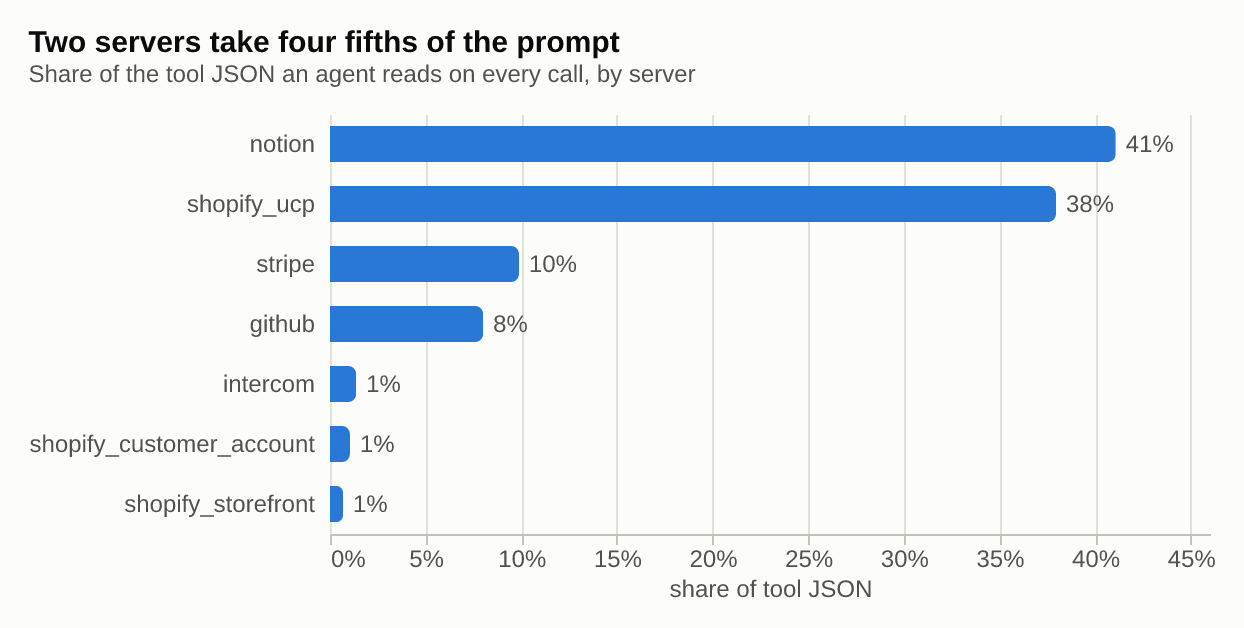

In [5]:
size = pd.Series(tp.tool_tokens_by_server())
charts.ranked_bars(size / size.sum(), "Two servers take four fifths of the prompt",
                   "Share of the tool JSON an agent reads on every call, by server", "share of tool JSON")

## The answer key

Bitext labels each message with an intent. The answer key maps each intent to tools:

- **acceptable**: a tool that is a right first call.
- **partial**: a sensible first step that doesn't finish the job, such as reading the FAQ.
- **gap**: no real tool can do it. The right answer is `hand_off_to_human`.
- **ask_ok**: a question back is also right, because every acceptable tool needs details the message
  usually doesn't give ("I want my money back": which order?).

In [6]:
lab = tp.labels()


def short(names: list[str]) -> str:
    """Tool names without their server prefix, comma separated."""
    return ", ".join(n.split(".")[-1] for n in names)


key = pd.DataFrame([{"intent": k, "no tool": v["gap"], "acceptable": short(v["acceptable"]), "ask_ok": v["ask_ok"],
                     "partial (count)": len(v["partial"])} for k, v in lab.items()]).sort_values(["no tool", "intent"])
print(f"{key['no tool'].sum()} of {len(key)} intents have no real tool")
key.set_index("intent")

14 of 27 intents have no real tool


,no tool,acceptable,ask_ok,partial (count)
intent,,,,
check_cancellation_fee,False,search_shop_policies_and_faqs,False,19
check_invoice,False,"list_invoices, get_order_status, get_most_recent_order_status, get_order, list_customers",False,15
check_payment_methods,False,search_shop_policies_and_faqs,False,20
check_refund_policy,False,search_shop_policies_and_faqs,False,19
contact_customer_service,False,"search_shop_policies_and_faqs, hand_off_to_human",False,19
delivery_options,False,search_shop_policies_and_faqs,False,20
delivery_period,False,"search_shop_policies_and_faqs, get_order_status, get_most_recent_order_status, get_order",False,16
get_invoice,False,"list_invoices, get_order_status, get_most_recent_order_status, get_order, list_customers",False,15
get_refund,False,"request_return, create_refund, get_order_status, get_most_recent_order_status, get_order, list_payment_int...",True,16


**14 of the 27 intents have no tool.** No official customer-side server can cancel a placed order, change an
address or delete an account. So about half the test is "know when nothing fits", which matters a lot for the
results and gets its own section in Part 5.

The key above is the **audited** one. I started with a first-pass key from reading the tool docs, ran the
selectors, then checked every failure by hand. Where the "failure" was the key's mistake, I changed the key
and wrote down why. The audit also marked three intents where a question back is a right answer (`ask_ok`).
Both versions are in `src/toolpick/data.py`, and you can score with either.

In [7]:
old = tp.labels("first_pass")
changed = [k for k in lab if set(lab[k]["acceptable"]) != set(old[k]["acceptable"]) or lab[k]["gap"] != old[k]["gap"]]
print(f"the audit changed the acceptable tools of {len(changed)} intents")
why = {intent: reason for intent, *_, reason in tp.data.AUDIT}
pd.DataFrame([{"intent": k, "first pass": short(old[k]["acceptable"]), "audited": short(lab[k]["acceptable"]), "why": why[k]}
              for k in changed]).set_index("intent")

the audit changed the acceptable tools of 6 intents


,first pass,audited,why
intent,,,
check_invoice,list_invoices,"list_invoices, get_order_status, get_most_recent_order_status, get_order, list_customers",For a shopper the bill is usually the order receipt; Stripe needs the customer before it can list their in...
contact_customer_service,search_shop_policies_and_faqs,"search_shop_policies_and_faqs, hand_off_to_human",'I want to call customer support': a person is customer service.
get_invoice,list_invoices,"list_invoices, get_order_status, get_most_recent_order_status, get_order, list_customers",Same as check_invoice.
get_refund,"request_return, create_refund","request_return, create_refund, get_order_status, get_most_recent_order_status, get_order, list_payment_int...","Both refund tools need an order or payment ID first, so the lookup is the right first call."
payment_issue,list_payment_intents,"list_payment_intents, hand_off_to_human",Someone reporting a payment problem should reach a person.
track_refund,hand_off_to_human,"get_order_status, get_most_recent_order_status, get_order, list_payment_intents",Looking up the order (or the payment) shows whether the refund went through; the routing policy itself say...


## Three messages to remember

One message a tool handles, one where a question is the right move, and one no tool can do. They come back
in the live run.

In [8]:
EXAMPLES = {"track_order": "F0091", "get_refund": "F0085", "cancel_order": "F0121"}
fresh_by_id = fresh.set_index("id")


def show_message(rid: str) -> None:
    """Print one message with what the answer key says about it."""
    r = fresh_by_id.loc[rid]
    v = lab[r.intent]
    print(f"{rid} [{r.intent}]  {r.text!r}")
    print(f"   right first call: {short(v['acceptable'])}" + ("  (or a question back)" if v["ask_ok"] else ""))
    print(f"   why: {v['note'][:230]}\n")


for rid in EXAMPLES.values():
    show_message(rid)

F0091 [track_order]  'will ushow me purchase ORD-480609 curret status'
   right first call: get_order_status, get_most_recent_order_status, get_order
   why: Exact fit. get_order_status needs an order number; get_most_recent_order_status takes none; UCP get_order needs an order GID and its output schema includes fulfillment tracking_number/tracking_url.

F0085 [get_refund]  'can uhelp me requesting reimbursements of my money'
   right first call: request_return, create_refund, get_order_status, get_most_recent_order_status, get_order, list_payment_intents  (or a question back)
   why: Two legitimate designs: customer-scoped return request on Shopify (refund follows the return), or merchant-authority refund of a Stripe PaymentIntent. Both are real; which one is 'right' depends on whether the assistant acts as th

F0121 [cancel_order]  'i can no longer pay fororder ORD-456953 cancel it'
   right first call: hand_off_to_human
   why: GAP. No official customer-facing MCP tool cancels a pla

# Part 2: the experiment

## What each selector is sent

**Jev** gets the message, one instruction, and the 91 options as `{name: description}`. It doesn't see the
input schemas. It returns a probability for each option and a confidence.

**The LLMs** run the way an agent really runs: a short system prompt, the 91 tools in the API's `tools`
parameter with their full schemas, and `tool_choice: auto`. The model may call a tool, call several, or
reply in text. That is called *native* tool calling here. (Part 4 also looks at *router* mode, where the
model is told to answer with one tool name and nothing else.)

Everyone gets the same **routing policy**: three rules that say what the store wants. Without it you are
measuring each model's guess at the policy, not its ability to follow one.

In [9]:
from toolpick.prompts import NATIVE_SYSTEM, POLICY, jev_instructions

print(NATIVE_SYSTEM, "\n")
print(POLICY)

You are the customer-support assistant for an online store. The store runs on Shopify, takes payments through Stripe and uses Intercom as its helpdesk; its staff also use GitHub and Notion. Help the customer using the tools available to you. If none of the tools can do what the customer asks, call hand_off_to_human. 

Routing policy:
1. The assistant serves the store's customers and may use the store's Shopify and Stripe tools to look up or act on that customer's orders, payments, refunds and invoices. If a tool can do what the customer wants, call it, even when the message is phrased as 'how do I ...?'.
2. Search the store's policies and FAQs only for questions about store policy: refunds, delivery, payment methods, fees, contact details.
3. If no tool can do what the customer wants (for example cancelling or editing a placed order, account changes, complaints, newsletters, reviews), pick hand_off_to_human. Don't search the FAQ instead.




One more thing went into the final setup. Real tool descriptions are written for developers ("This tool will
fetch a list of Invoices from Stripe"). Customers say "download my bill". So six tools got one extra line in
customers' words. I wrote those lines while looking at the first sample's misses, which is exactly why the
final results use messages the lines have never seen.

In [10]:
from toolpick.data import CUSTOMER_WORDS

for name, line in CUSTOMER_WORDS.items():
    print(f"{name.split('.')[-1]:32s} {line}")

search_catalog                   Customers say: 'I want to buy an article', 'help me order some items', 'I need to shop for a product'.
create_cart                      Customers say: 'I want to buy this', 'add it to my cart'.
list_invoices                    Customers say: 'where is my invoice', 'download my bill #123', 'check my bills'.
get_order_status                 Customers say: 'status of order ORD-123', 'check bill/invoice #123', 'any news on my refund for order ...'.
get_most_recent_order_status     Customers say: 'where is my order', 'any news on my refund', 'I'm waiting for my reimbursement'.
request_return                   Customers say: 'I want my money back', 'how do I get a refund', 'I want a compensation'.


Here is the request for one message, with the long parts cut. The same builder (`toolpick.live`) made every
call in the committed runs. Things to notice: temperature 0, a cache marker on the system prompt so the 76,000
tokens of tools are billed at the cached rate after the first call, and tool names with `__` because function
names can't contain the dots MCP names have.

In [11]:
from toolpick.live import native_request

final_tools = tp.tools(customer_words=True)
kwargs, _ = native_request("sonnet", fresh_by_id.loc["F0085"].text, final_tools, tp.prompts.native_system(True))
print({k: v for k, v in kwargs.items() if k not in ("messages", "tools")})
print("user message:", kwargs["messages"][1]["content"])
print(len(kwargs["tools"]), "tools, the first:", json.dumps(kwargs["tools"][0])[:230], "...")
print()
print("Jev's question:", jev_instructions(True)[-150:])
print("Jev's options: ", len(final_tools), "of the form", {final_tools[0]["name"]: final_tools[0]["description"][:60] + "..."})

{'model': 'anthropic/claude-sonnet-5.5', 'max_tokens': 400, 'temperature': 0, 'tool_choice': 'auto', 'extra_body': {'usage': {'include': True}, 'reasoning': {'effort': 'low'}}}
user message: can uhelp me requesting reimbursements of my money
91 tools, the first: {"type": "function", "function": {"name": "shopify_storefront__search_shop_policies_and_faqs", "description": "Used to get facts about the stores policies, products, or services.\nSome examples of questions you can ask are:\n  - W ...

Jev's question: ld an online store's customer-support assistant call first for this customer message? Pick hand_off_to_human if no tool can do what the customer asks.
Jev's options:  91 of the form {'shopify_storefront.search_shop_policies_and_faqs': 'Used to get facts about the stores policies, products, or se...'}


## A small live run

`run_live` is the whole experiment loop. It asks one selector about each message and appends each answer to a
file as it arrives, so a crash loses nothing and a re-run skips what is done. The first call goes alone so that
it writes the provider's prompt cache and the rest read it. A budget stops the loop if spending passes a cap.

`LIVE_ARMS` lists who gets called. Jev and DeepSeek cost a cent or less for five messages. Haiku and Sonnet work
the same way, but Sonnet's first call pays to write a 76,000-token cache (19 US cents in the committed run), so
they are left out by default.

In [12]:
LIVE_ARMS = ["jev", "deepseek"]  # add "haiku" and "sonnet" for about 25 cents more
LIVE_IDS = ["F0091", "F0085", "F0121", "F0040", "F0083"]  # the three examples, an invoice and a complaint
RUN_NAME = {"jev": "jev", "deepseek": "native_deepseek", "haiku": "native_haiku", "sonnet": "native_sonnet"}
KEY_FOR = {"jev": "TYPESAFE_API_KEY"}  # every other arm goes through OpenRouter


def run_live(arm: str, reqs: list, out, workers: int = 4, budget_usd: float = 0.50) -> None:
    """Ask one selector about each message; append each answer to `out` as it arrives; skip ids already there."""
    from toolpick.live import ask

    out.parent.mkdir(parents=True, exist_ok=True)
    done = {json.loads(line)["id"] for line in out.read_text().splitlines()} if out.exists() else set()
    todo = [r for r in reqs if r.id not in done]
    spent, lock = [0.0], threading.Lock()

    def one(r) -> None:
        if spent[0] >= budget_usd:
            return
        row = {"id": r.id, **ask(arm, r.text)}
        with lock, out.open("a") as f:
            spent[0] += row["cost_usd"]
            f.write(json.dumps(row) + "\n")

    for r in todo[:1]:
        one(r)
    with ThreadPoolExecutor(workers) as pool:
        list(pool.map(one, todo[1:]))
    tp.load_run.cache_clear()
    print(f"{arm}: {len(todo)} new calls, ${spent[0]:.4f}")

In [13]:
live_reqs = [r for r in tp.requests("fresh") if r.id in LIVE_IDS]
ran = []
for arm in LIVE_ARMS:
    if os.getenv(KEY_FOR.get(arm, "OPENROUTER_API_KEY")):
        run_live(arm, live_reqs, tp.RUNS / "live" / f"{RUN_NAME[arm]}.jsonl")
        ran.append(arm)
    else:
        print(f"{arm}: no key, skipped")

jev: 5 new calls, $0.0015


deepseek: 5 new calls, $0.0013


Now score the live answers exactly as the committed runs are scored, and put them beside what the same
selector answered on 23 October 2026. All calls use temperature 0, so the picks should mostly repeat.

In [14]:
rows = []
for arm in ran:
    before = tp.load_run(f"fresh/{RUN_NAME[arm]}")
    for r in tp.scored_rows(f"live/{RUN_NAME[arm]}"):
        then = before[r["id"]]["pick"]
        rows.append({"selector": tp.MODEL_NAMES[arm], "message": r["text"][:48], "intent": r["intent"],
                     "pick today": short([r["pick"] or "(asks a question)"]), "outcome": r["outcome"],
                     "same as 23 Oct": r["pick"] == then, "seconds": round(r["latency_s"], 2), "US$": round(r["cost_usd"], 5)})
live = pd.DataFrame(rows)
if len(live):
    print(f"{live['same as 23 Oct'].sum()} of {len(live)} picks are the same as in the committed run; "
          f"total ${live['US$'].sum():.4f}")
live if len(live) else print("no live calls were made: set the keys to try it")

10 of 10 picks are the same as in the committed run; total $0.0028


,selector,message,intent,pick today,outcome,same as 23 Oct,seconds,US$
0,Jev,i need asssistance getting my bill #37777,get_invoice,get_order_status,right,True,0.49,0.00030
1,Jev,"my experience with you was too bad, help making",complaint,hand_off_to_human,right,True,0.27,0.00030
2,Jev,will ushow me purchase ORD-480609 curret status,track_order,get_order_status,right,True,0.35,0.00030
3,Jev,can uhelp me requesting reimbursements of my mon,get_refund,request_return,right,True,0.35,0.00030
4,Jev,i can no longer pay fororder ORD-456953 cancel i,cancel_order,hand_off_to_human,right,True,0.46,0.00030
5,DeepSeek V4.1 Flash,i need asssistance getting my bill #37777,get_invoice,list_invoices,right,True,3.40,0.00024
6,DeepSeek V4.1 Flash,can uhelp me requesting reimbursements of my mon,get_refund,get_most_recent_order_status,right,True,1.20,0.00024
7,DeepSeek V4.1 Flash,will ushow me purchase ORD-480609 curret status,track_order,get_order_status,right,True,1.85,0.00024
8,DeepSeek V4.1 Flash,i can no longer pay fororder ORD-456953 cancel i,cancel_order,get_order_status,defensible,True,1.95,0.00025
9,DeepSeek V4.1 Flash,"my experience with you was too bad, help making",complaint,hand_off_to_human,right,True,2.52,0.00030


All ten picks match the October run. Two rows preview Part 4. On the refund message Jev picks `request_return`
straight away, while DeepSeek looks up the latest order first. And on the cancellation, which no tool can do,
Jev hands off and DeepSeek checks the order's status instead: a benign miss.

A practical note on cost. The first call to an LLM after a quiet spell writes the provider's prompt cache and
costs many times more than the calls that read it (0.7 US cents against 0.02 the first time I ran this cell).
That is why `run_live` sends the first message alone.

## The full run

The committed runs are this same loop over all 600 fresh messages, on 23 October 2026. The table shows what
each cost then, from the billed usage in every API response. Jev only picks the tool, so its row includes a
second call (to DeepSeek) that fills in the arguments of the tool it picked; the LLM agents do both in one call.

In [15]:
RUNS = {"Jev": "fresh/jev", "Claude Sonnet 5.5": "fresh/native_sonnet", "Claude Haiku 5.5": "fresh/native_haiku",
        "DeepSeek V4.1 Flash": "fresh/native_deepseek"}
scored = {name: pd.DataFrame(tp.scored_rows(run)) for name, run in RUNS.items()}


def wall_minutes(run: str) -> float:
    """Minutes from the first call to the last, from the timestamps stored with each answer."""
    ts = sorted(datetime.fromisoformat(r["ts"]) for r in tp.load_run(run).values())
    return (ts[-1] - ts[0]).total_seconds() / 60


bill = pd.DataFrame({name: {"calls": len(d), "billed US$": d.cost_usd.sum(), "US$ per 1,000": 1000 * d.cost_usd.mean(),
                            "input tokens per call": d.input_tokens.median(), "minutes": wall_minutes(RUNS[name])}
                     for name, d in scored.items()}).T
print(f"the full run cost ${bill['billed US$'].sum():.2f}")
bill.style.format({"calls": "{:.0f}", "billed US$": "${:.2f}", "US$ per 1,000": "${:.2f}", "input tokens per call": "{:,.0f}",
                   "minutes": "{:.0f}"})

the full run cost $6.32


,calls,billed US$,"US$ per 1,000",input tokens per call,minutes
Jev,600,$0.20,$0.34,"7,736",1
Claude Sonnet 5.5,600,$5.44,$9.07,"76,222",5
Claude Haiku 5.5,600,$0.51,$0.85,"76,221",4
DeepSeek V4.1 Flash,600,$0.17,$0.28,"51,609",6


Sonnet is 86% of the bill. To run all of it again, set `FULL_RUN = True`. The answers go to a new dated folder,
so the committed runs are never overwritten, and you can point `RUNS` (above) at the new folder to analyse
your own run with the rest of this notebook. **This cell was not run for the committed notebook**: it is the
only part that costs real money.

In [16]:
FULL_RUN = False  # True spends about US$6 and takes about a quarter of an hour
BUDGET_USD = {"jev": 0.50, "deepseek": 1.00, "haiku": 2.00, "sonnet": 8.00}

if FULL_RUN:
    folder = f"rerun/{date.today().isoformat()}"
    for arm in ["jev", "deepseek", "haiku", "sonnet"]:
        run_live(arm, tp.requests("fresh"), tp.RUNS / folder / f"{RUN_NAME[arm]}.jsonl", workers=8, budget_usd=BUDGET_USD[arm])
    print(f"done: set RUNS to the files under runs/{folder}/ to analyse them")
else:
    print("FULL_RUN is off: the analysis below uses the committed runs of 23 October 2026")

FULL_RUN is off: the analysis below uses the committed runs of 23 October 2026


# Part 3: the results

## Scoring one answer

Accuracy alone hides the thing a support lead cares about: *what happened when it was wrong?* So each answer
gets one of six outcomes, which fold into three verdicts.

| verdict | outcome | what happened |
|---|---|---|
| **correct** | `right` | an acceptable tool (or, where the key allows, a question back) |
| **benign** | `defensible` | a sensible first step that doesn't finish the job, such as reading the FAQ |
| | `handed_off` | gave it to a person although a tool could have done it |
| | `asked` | asked the customer a question where that isn't the right first step |
| **harmful** | `wrong` | a tool that can't do the job, where a right tool exists |
| | `bluffed` | a tool call on a request no tool can handle |

Benign misses cost time. Harmful ones look like progress and aren't. The cell scores five possible answers to
two of our example messages.

In [17]:
picks = ["shopify_customer_account.get_order_status", "shopify_storefront.search_shop_policies_and_faqs", tp.HAND,
         "stripe.create_refund", None]
pd.DataFrame({intent: {short([p]) if p else "(asks a question)": tp.outcome(p, lab[intent], "tool_call" if p else "text")
                       for p in picks} for intent in ("track_order", "get_refund", "cancel_order")})

,track_order,get_refund,cancel_order
get_order_status,right,right,defensible
search_shop_policies_and_faqs,defensible,defensible,defensible
hand_off_to_human,handed_off,handed_off,right
create_refund,wrong,right,bluffed
(asks a question),asked,right,asked


Read across the `hand_off_to_human` row: the same answer is a miss for `track_order` and exactly right for
`cancel_order`. And `create_refund` is right for a refund request, harmful anywhere else.

## The headline

Final setup, 600 fresh messages, audited answer key.

,correct,benign,harmful,harmful_n,asked a question,handed off,95% CI low,95% CI high
Jev,95.3%,4.5%,0.2%,1,0.0%,61.0%,93.3%,96.8%
Claude Sonnet 5.5,93.3%,6.7%,0.0%,0,4.5%,52.0%,91.0%,95.1%
Claude Haiku 5.5,82.2%,17.8%,0.0%,0,13.0%,41.7%,78.9%,85.0%
DeepSeek V4.1 Flash,47.2%,52.5%,0.3%,2,36.3%,7.5%,43.2%,51.2%


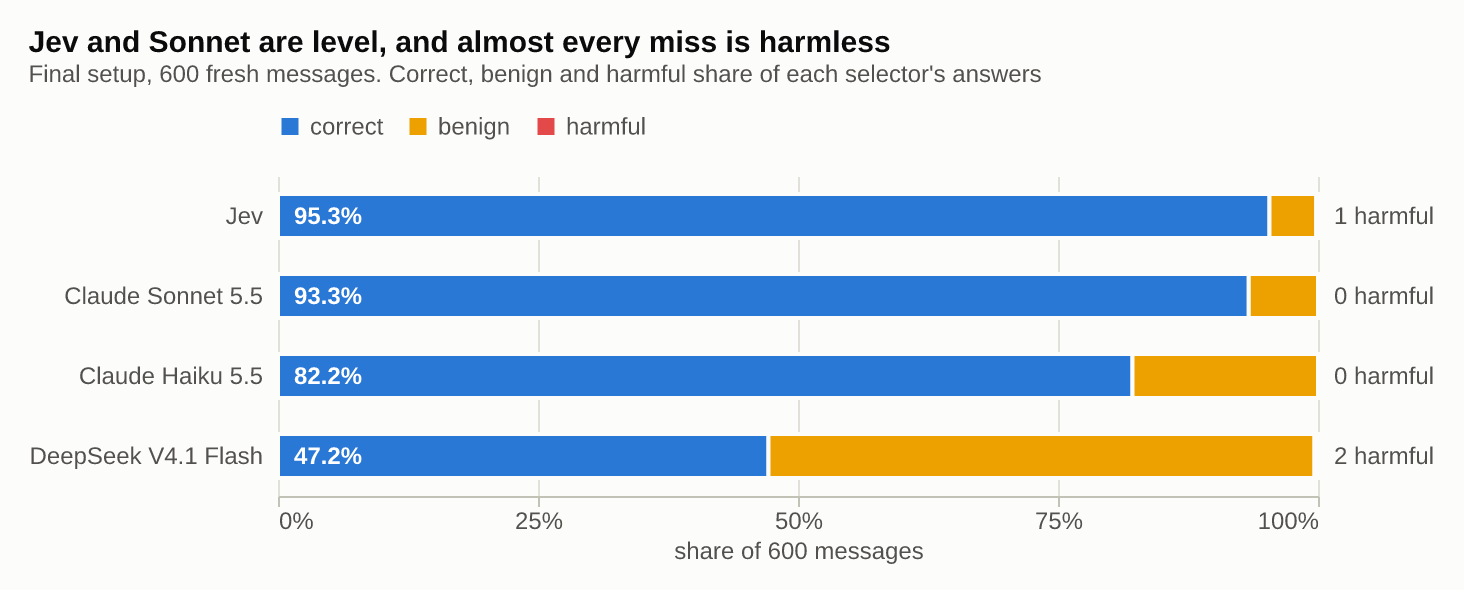

In [18]:
def headline(runs: dict[str, str], version: str = "audited") -> pd.DataFrame:
    """One row per selector: the three verdicts, how often it asked or handed off, and the harmful count."""
    out = {}
    for name, run in runs.items():
        rows = tp.scored_rows(run, version)
        s = tp.summarise(rows)
        out[name] = {"correct": s["correct"], "benign": s["benign"], "harmful": s["harmful"],
                     "harmful_n": sum(r["wrong_call"] for r in rows), "asked a question": s["asked"], "handed off": s["handoff"],
                     "95% CI low": s["right_ci"][0], "95% CI high": s["right_ci"][1]}
    return pd.DataFrame(out).T.astype({"harmful_n": int})


PCT = {c: "{:.1%}" for c in ["correct", "benign", "harmful", "asked a question", "handed off", "95% CI low", "95% CI high"]}
table = headline(RUNS)
display(table.style.format(PCT))
charts.outcome_bars(table, "Jev and Sonnet are level, and almost every miss is harmless",
                    "Final setup, 600 fresh messages. Correct, benign and harmful share of each selector's answers")

Three things to read off it:

1. **Jev (95.3%) and Sonnet (93.3%) are at the top, two points apart.** Whether two points is a real gap is
   the next section.
2. **Harm is rare for everyone**: 3 harmful answers in 2,400. With a clear policy and a hand-off option, these
   selectors fail safe.
3. **DeepSeek's 47% is not 53% wrong calls.** It asked the customer a question on 36% of messages and took a
   "defensible" first step on most of the rest. Part 4 shows that this is about *how it was run*, not only
   about the model.

## Is two points a real gap?

Both selectors answered the *same* 600 messages, so their scores aren't independent, and comparing the two
intervals in the table is the wrong test. The right one looks only at the messages where exactly one of the
two was right (an exact McNemar test). If Jev and Sonnet were equally good, those messages would split like
coin flips.

In [19]:
def versus(a: str, b: str) -> dict:
    """A paired comparison of two runs on the same messages."""
    p = tp.paired(RUNS[a], RUNS[b])
    return {"comparison": f"{a} vs {b}", "difference": p["diff"], "only first right": p["only_a"], "only second right": p["only_b"],
            "p (McNemar)": p["p"], "95% CI low": p["ci"][0], "95% CI high": p["ci"][1]}


pairs = pd.DataFrame([versus("Jev", other) for other in list(RUNS)[1:]]).set_index("comparison")
pairs.style.format({"difference": "{:+.1%}", "p (McNemar)": "{:.2g}", "95% CI low": "{:+.1%}", "95% CI high": "{:+.1%}"})

,difference,only first right,only second right,p (McNemar),95% CI low,95% CI high
comparison,,,,,,
Jev vs Claude Sonnet 5.5,+2.0%,37,25,0.16,-0.7%,+4.5%
Jev vs Claude Haiku 5.5,+13.2%,102,23,4.6e-13,+9.7%,+16.8%
Jev vs DeepSeek V4.1 Flash,+48.2%,308,19,2.2e-68,+43.5%,+52.8%


Jev was the only one right on 37 messages and Sonnet on 25. A split that uneven or worse happens by chance
about one time in six (p = 0.16), and the interval on the difference runs from slightly below zero to +4.5
points. **So it's a tie, not a win.** The gaps to Haiku and DeepSeek are not chance.

The honest headline is therefore: *a small choice model matched the best LLM agent tested, on this task, at a
fraction of the cost* (Part 6), not "Jev beats Sonnet".

# Part 4: why

## Where each selector is right

Split the messages by whether any real tool can handle them. This is the most informative cut of the data.

289 messages a tool can handle, 311 that no tool can


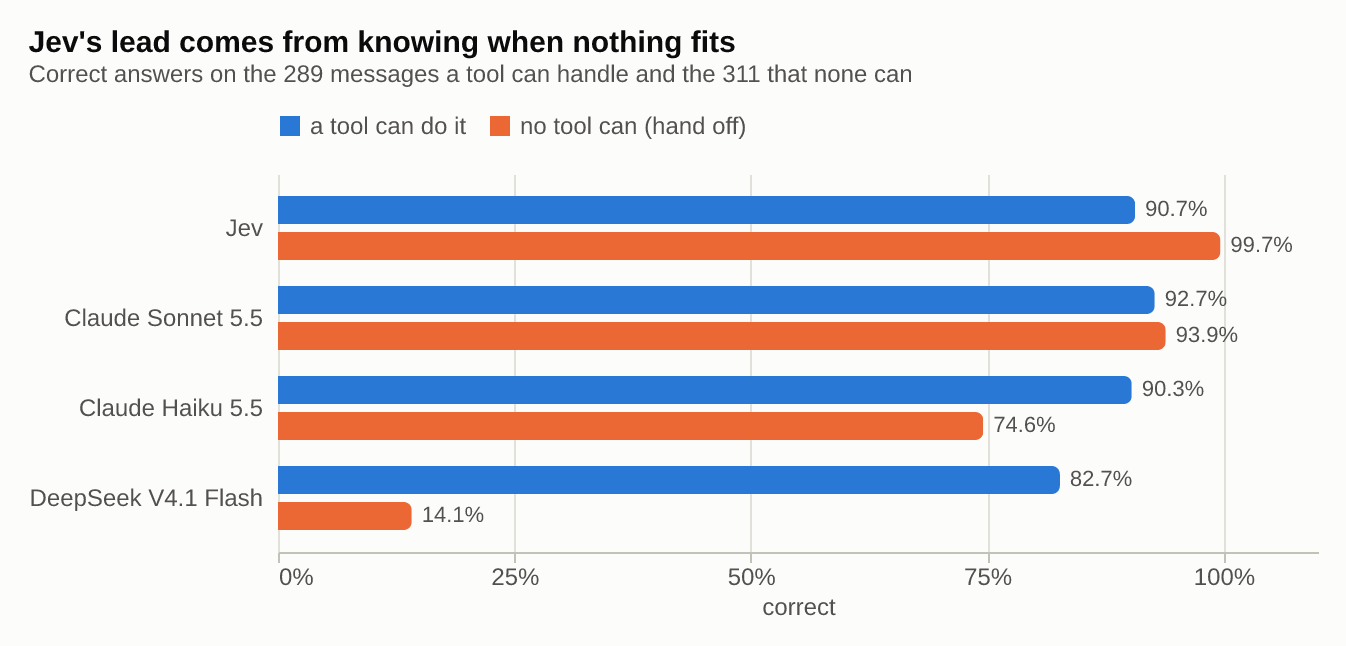

In [20]:
KINDS = ["a tool can do it", "no tool can (hand off)"]
split = pd.DataFrame({name: {KINDS[0]: d[~d.gap].right.mean(), KINDS[1]: d[d.gap].right.mean()} for name, d in scored.items()}).T
n_gap = int(scored["Jev"].gap.sum())
print(f"{len(fresh) - n_gap} messages a tool can handle, {n_gap} that no tool can")
charts.split_bars(split, "Jev's lead comes from knowing when nothing fits",
                  "Correct answers on the 289 messages a tool can handle and the 311 that none can")

On the messages a tool *can* handle, Sonnet is a little ahead of Jev (93% against 91%), and Haiku is level
with Jev. Jev's overall lead comes entirely from the other half: it hands off almost perfectly, where Sonnet
sometimes asks a question or reads the FAQ first, and the cheaper agents do so often.

So what does each selector do when it isn't right?

In [21]:
mix = pd.DataFrame({name: d.outcome.value_counts() for name, d in scored.items()}).T.reindex(columns=tp.OUTCOMES).fillna(0).astype(int)
mix

outcome,right,defensible,handed_off,asked,wrong,bluffed
Jev,572,1,26,0,1,0
Claude Sonnet 5.5,560,8,5,27,0,0
Claude Haiku 5.5,493,23,6,78,0,0
DeepSeek V4.1 Flash,283,97,0,218,0,2


Jev's misses are hand-offs: it is cautious. The agents' misses are questions and FAQ searches: they are
helpful in the wrong direction. Here are three of DeepSeek's questions on requests the policy says to hand
off. They are polite, reasonable, and not what the store asked for.

In [22]:
d = scored["DeepSeek V4.1 Flash"]
d[(d.outcome == "asked") & d.gap][["intent", "text", "reply"]].sample(3, random_state=3).assign(reply=lambda x: x.reply.str.slice(0, 200))

,intent,text,reply
228,registration_problems,assistance signing up,I'd be happy to help you sign up! Could you tell me a bit more about what you're trying to sign up for?\n\...
374,contact_human_agent,chatting with humnan agent,"I'm here to help! I'm an assistant for the store, and I can help you with things like:\n\n- **Orders & shi..."
353,create_account,new Basic acount,"I'd be happy to help you with a new Basic account! However, I want to make sure I point you in the right d..."


## The same model, run two ways

DeepSeek was also run on the fresh messages as a **router**: the tool list pasted into the prompt as JSON, and
an instruction to reply with one tool name. Same model, same messages, same policy, same tools.

In [23]:
modes = headline({"DeepSeek as a router (name one tool)": "fresh/router_deepseek", "DeepSeek as an agent (native tools)": "fresh/native_deepseek"})
p = tp.paired("fresh/router_deepseek", "fresh/native_deepseek")
print(f"router minus agent: {p['diff']:+.1%}, p = {p['p']:.1g}")
modes[["correct", "benign", "harmful", "asked a question", "handed off"]].style.format(PCT)

router minus agent: +43.7%, p = 3e-59


,correct,benign,harmful,asked a question,handed off
DeepSeek as a router (name one tool),90.8%,9.0%,0.2%,0.0%,63.0%
DeepSeek as an agent (native tools),47.2%,52.5%,0.3%,36.3%,7.5%


**Forty-four points from the mode alone.** As a router DeepSeek scores 91%, within five points of Jev. Given
the freedom to reply in text, it uses it. That is the biggest effect in the whole study, and it is bigger than
the difference between any two models.

It cuts both ways, and Part 5 returns to it: the headline compares Jev (which *must* pick an option) with agents
(which may ask). The comparison is the realistic one, since that is how each is deployed, but it is not a
like-for-like comparison of models.

## How the setup got here

The final setup wasn't the first one. These are the development runs on the first 600 messages: each selector
with and without the routing policy, scored with the audited key.

In [24]:
dev = []
for run in tp.available_runs():
    m = tp.parse_run_name(run)
    if m["prompt"] in ("base", "policy"):
        s = tp.summarise(tp.scored_rows(run))
        dev.append({"selector": f"{tp.MODEL_NAMES[m['model']]} ({m['mode']})" if m["mode"] != "jev" else "Jev", "prompt": m["prompt"],
                    "correct": s["correct"], "harmful": s["harmful"], "n": s["n"]})
dev = pd.DataFrame(dev).pivot(index="selector", columns="prompt", values=["correct", "harmful"])
dev[("correct", "gain")] = dev[("correct", "policy")] - dev[("correct", "base")]
dev.sort_values(("correct", "policy"), ascending=False).style.format("{:.1%}")

**Writing the policy down helped every selector**, by 7 to 33 points, and it took Haiku's harmful answers as a
router from 7% to under 1%. Without the policy, each model was guessing what the store wanted, and I was
scoring the guess. (Sonnet as a router ran on 300 messages, to save money; the rest ran on 600.)

The second change was the answer key itself. The same development runs, scored with the key before and after
the audit:

In [25]:
keys = pd.DataFrame({run: {"first-pass key": tp.summarise(tp.scored_rows(run, "first_pass"))["correct"],
                           "audited key": tp.summarise(tp.scored_rows(run))["correct"]}
                     for run in ["jev_policy", "router_sonnet_policy", "native_sonnet_policy", "native_haiku_policy"]}).T
keys.assign(change=keys["audited key"] - keys["first-pass key"]).style.format("{:+.1%}", subset=["change"]).format(
    "{:.1%}", subset=["first-pass key", "audited key"])

,first-pass key,audited key,change
jev_policy,82.2%,85.5%,+3.3%
router_sonnet_policy,85.0%,92.7%,+7.7%
native_sonnet_policy,77.7%,92.2%,+14.5%
native_haiku_policy,70.0%,85.2%,+15.2%


The audit moved these scores by 3 to 15 points and changed the ranking: under the first-pass key Jev is ahead
of Sonnet as an agent, and under the audited key Sonnet is ahead by seven points. Most of the movement is the
agents. The first-pass key marked a question back as wrong everywhere, and marked "look up the order" as wrong
for a refund request, where it is the sensible first call. With the unaudited key I would have reported that
the best agent was behind, for reasons that were my labelling and not its behaviour.

The third change was the customer wording. Jev was handing off requests a tool could do, so I tried eight
variations of its question on 201 development messages, changing one thing at a time, and then checked the
ones that helped on the 399 messages they hadn't been tuned on.

In [26]:
VARIANTS = {"baseline": "the policy setup, run again", "handoff_first": "hand-off option listed first",
            "shuffled": "options in a random order", "handoff_desc": "a narrower hand-off description",
            "no_handoff_line": "no 'pick hand-off if...' sentence", "no_distractors": "GitHub and Notion tools removed",
            "descriptions": "customer wording on six tools", "combined": "narrow hand-off + no line + customer wording"}
exp = []
for v, what in VARIANTS.items():
    held = tp.scored_rows(f"experiments/jev_{v}_held")
    exp.append({"variant": v, "what changed": what, "dev 201": tp.summarise(tp.scored_rows(f"experiments/jev_{v}_dev"))["correct"],
                "held-out 399": tp.summarise(held)["correct"] if held else None})
again, original = tp.load_run("experiments/jev_baseline_dev"), tp.load_run("jev_policy")
print(f"the same setup run twice: {sum(original[i]['pick'] == r['pick'] for i, r in again.items())} of {len(again)} picks identical")
pd.DataFrame(exp).set_index("variant").style.format({"dev 201": "{:.1%}", "held-out 399": "{:.1%}"}, na_rep="not run")

the same setup run twice: 193 of 201 picks identical


,what changed,dev 201,held-out 399
variant,,,
baseline,"the policy setup, run again",86.1%,not run
handoff_first,hand-off option listed first,86.6%,not run
shuffled,options in a random order,89.1%,not run
handoff_desc,a narrower hand-off description,88.6%,88.5%
no_handoff_line,no 'pick hand-off if...' sentence,89.1%,not run
no_distractors,GitHub and Notion tools removed,87.1%,not run
descriptions,customer wording on six tools,97.0%,96.7%
combined,narrow hand-off + no line + customer wording,98.0%,97.2%


Order, the hand-off wording and the distractors moved the score by three points at most. What mattered was the
words: one line of customer language on six tools added eleven points, and it held up on the messages it wasn't
written from (96.7%). The `baseline` row is the policy setup simply run again: 8 of 201 picks came out
different from the first time. That is the noise floor, and the small effects above are not far from it.

## Jev's confidence

Jev returns a confidence with each pick. If it is honest, low confidence should mean "more likely wrong".

In [27]:
jev = scored["Jev"].assign(band=lambda x: pd.cut(x.confidence, [0, 0.5, 0.7, 0.9, 1.01], right=False,
                                                 labels=["below 0.5", "0.5 to 0.7", "0.7 to 0.9", "0.9 and up"]))
jev.groupby("band", observed=True)["right"].agg(messages="size", correct="mean").style.format({"correct": "{:.1%}"})

,messages,correct
band,,
below 0.5,31,80.6%
0.5 to 0.7,80,87.5%
0.7 to 0.9,132,93.2%
0.9 and up,357,99.2%


It is: accuracy climbs with confidence. An obvious design follows: let Jev answer when it is sure, and send
the rest to Sonnet. This cell tries that cascade at several thresholds.

In [28]:
sonnet = scored["Claude Sonnet 5.5"].set_index("id")
j = scored["Jev"].set_index("id")
cascade = []
for t in [0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.01]:
    up = j.confidence < t  # these go to Sonnet
    right = (j.right & ~up) | (sonnet.right.reindex(j.index) & up)
    cost = j.pick_cost_usd.sum() + j.fill_cost_usd[~up].sum() + sonnet.cost_usd.reindex(j.index)[up].sum()
    cascade.append({"send to Sonnet below": f"{t:.1f}" if t <= 1 else "everything", "sent to Sonnet": up.mean(), "correct": right.mean(),
                    "US$ per 1,000": 1000 * cost / len(j)})
pd.DataFrame(cascade).set_index("send to Sonnet below").style.format({"sent to Sonnet": "{:.0%}", "correct": "{:.1%}", "US$ per 1,000": "${:.2f}"})

,sent to Sonnet,correct,"US$ per 1,000"
send to Sonnet below,,,
0.0,0%,95.3%,$0.34
0.5,5%,95.7%,$0.79
0.6,11%,96.0%,$1.29
0.7,18%,95.0%,$1.97
0.8,27%,95.5%,$2.73
0.9,40%,95.0%,$3.89
everything,100%,93.3%,$9.37


**The cascade buys almost nothing.** The best threshold gains well under a point for nearly four times the
cost, and that is inside the noise. The reason is in the split above: where Jev is unsure, Sonnet isn't
reliably better. I expected this to be the clever result of the study, and it isn't one. A cascade only pays
when the second model is clearly stronger on exactly the cases the first one doubts.

## Are the arguments right too?

Picking the tool is half a tool call. The other half is the arguments. There is no answer key for those, so
the check is by rule (`src/toolpick/arguments.py`): the arguments fit the tool's schema, every order number or
ID comes from the message rather than being made up, an order number in the message is passed on, and Stripe
amounts are in cents. It runs on every call to a correct tool other than a hand-off.

In [29]:
args = []
for name, d in scored.items():
    checked = d[d.right & d.args_ok.notna() & (d["pick"] != tp.HAND)]
    args.append({"selector": name, "right tool": d.right.mean(), "calls checked": len(checked), "arguments pass": int(checked.args_ok.sum()),
                 "right tool and arguments": (d.right & ~d.args_ok.eq(False)).mean()})
display(pd.DataFrame(args).set_index("selector").style.format({"right tool": "{:.1%}", "right tool and arguments": "{:.1%}"}))
bad = scored["Jev"][scored["Jev"].right & scored["Jev"].args_ok.eq(False)]
bad[["text", "pick", "args_problems"]].head(3).assign(pick=lambda x: x["pick"].map(lambda p: short([p])))

,right tool,calls checked,arguments pass,right tool and arguments
selector,,,,
Jev,95.3%,232,219,93.2%
Claude Sonnet 5.5,93.3%,215,215,93.3%
Claude Haiku 5.5,82.2%,200,200,82.2%
DeepSeek V4.1 Flash,47.2%,185,180,46.3%


,text,pick,args_problems
85,can uhelp me requesting reimbursements of my money,request_return,not in the message: line_item_id='unknown'
103,wanna get a rebate of my mney,request_return,not in the message: line_item_id='unknown'
113,obtain money back,request_return,not in the message: line_item_id='unknown'


With arguments counted, Jev and Sonnet are level at 93%. Jev's failures are all one kind: the customer says "I
want my money back", Jev picks a return or refund tool (which the key accepts), and the second call, forced to
fill in that tool, invents the order line it needs. An agent in the same spot asks which order. A picker that
can't ask is a real limit of the pick-then-fill design.

# Part 5: what could be wrong with this study

A result is only as good as the checks it survived. These are the ones I ran against this one, each with its
number. Several of them weaken the headline, and they should.

## 1. Is this tool selection, or intent classification?

The answer key is per intent. So a system that recognises the intent and looks the tool up in the key would
score well without reading a single tool description. Two baselines measure how far that goes
(`scripts/baseline_intent_nb.py`; no API calls): always hand off, and a bag-of-words naive Bayes classifier
trained on the rest of Bitext that guesses the intent and then reads the answer key.

naive Bayes gets the intent right on 88.7% of fresh messages, trained on 22,317 others
naive Bayes vs Jev: p = 1.00; vs Sonnet: p = 0.21


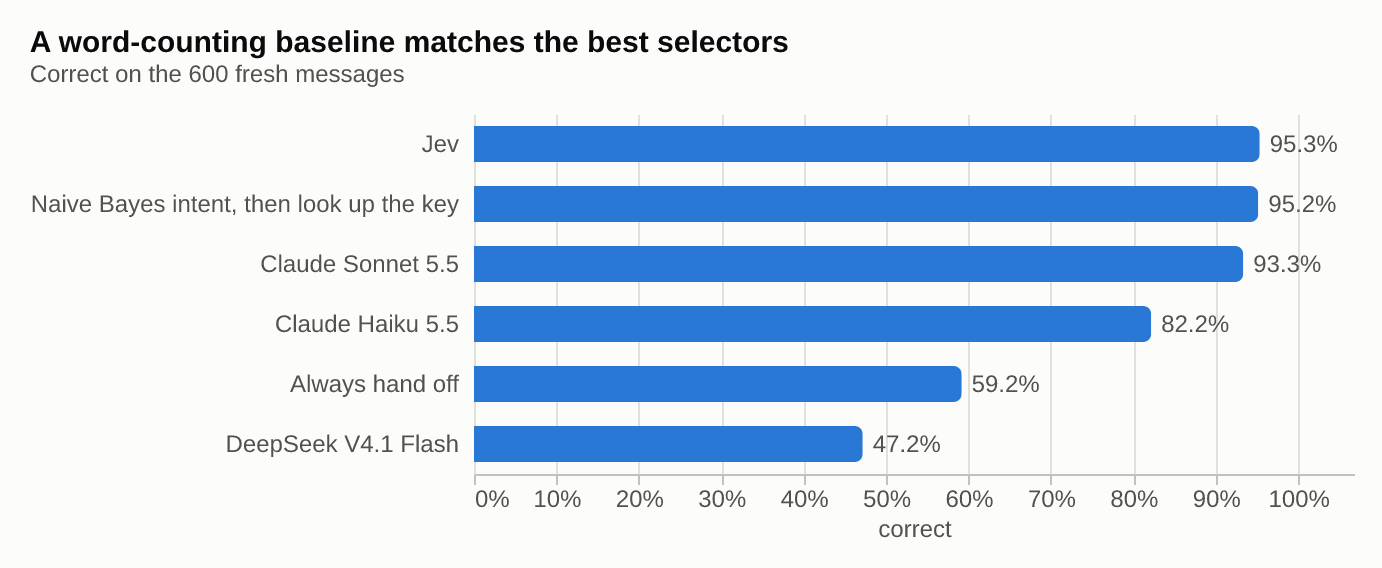

In [30]:
base = json.loads((tp.DATA / "baselines.json").read_text())
ref = pd.Series({"Always hand off": base["always_hand_off"],
                 "Naive Bayes intent, then look up the key": base["nb_tool_correct"], **table["correct"].to_dict()})
print(f"naive Bayes gets the intent right on {base['nb_intent_accuracy']:.1%} of fresh messages, trained on {base['train_rows']:,} others")
print(f"naive Bayes vs Jev: p = {base['nb_vs_jev']['p']:.2f}; vs Sonnet: p = {base['nb_vs_sonnet']['p']:.2f}")
charts.ranked_bars(ref, "A word-counting baseline matches the best selectors", "Correct on the 600 fresh messages", "correct", ".1%")

**A word-counting classifier from the 1960s ties with both leaders.** It isn't a fair rival: it is trained on 22,000 labelled messages
from the same templates and it reads the answer key, while Jev and the agents see only tool descriptions. But
it shows what this benchmark mostly measures: recognising a templated intent. If you have labelled history and
a fixed set of intents, you may not need a model to pick tools at all. The zero-shot selectors earn their keep
when the tools change and there is no history, which this data can't test.

And always handing off scores 59%, because half the requests have no tool. Any accuracy here should be read
against 59%, not against zero.

## 2. The ranking depends on the mix of requests

Jev is better on no-tool requests and Sonnet on the rest, so who "wins" depends on how many of each you have.
The lines below reweight the two halves of the fresh sample.

the lines cross at 26%; this sample has 52% no-tool requests


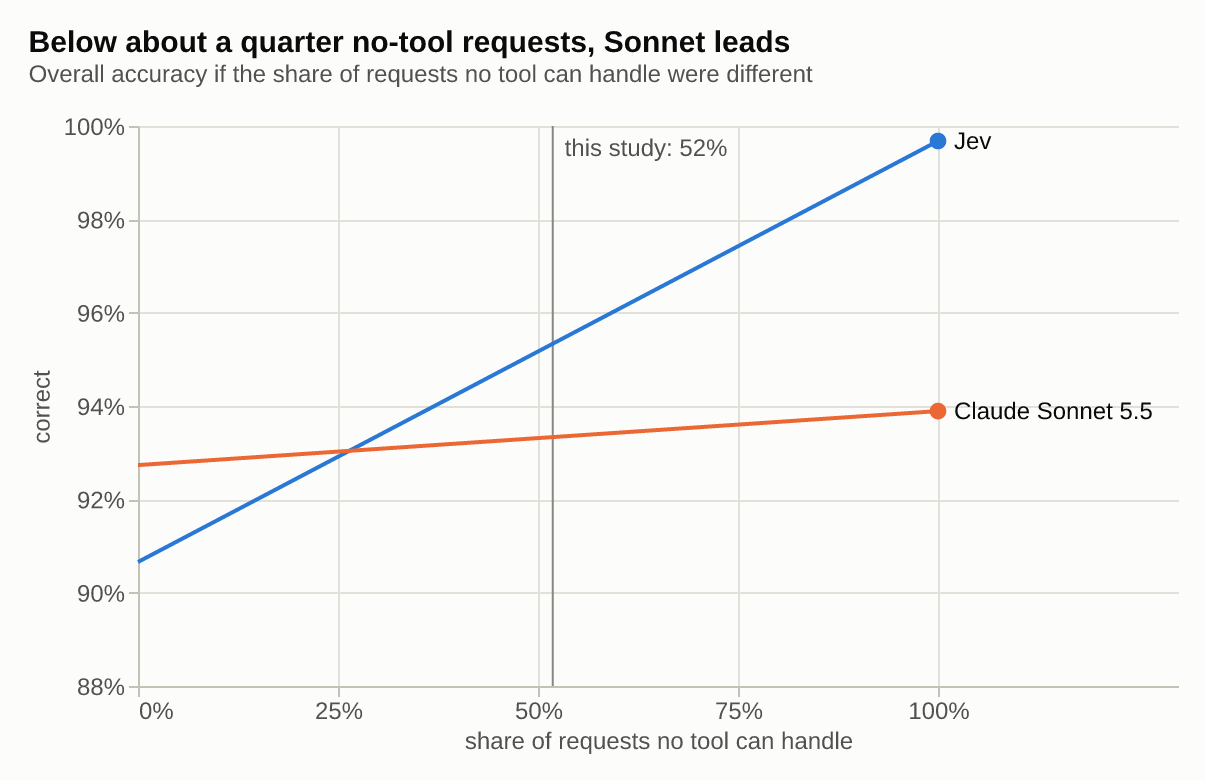

In [31]:
here = scored["Jev"].gap.mean()
lines = pd.DataFrame([{"selector": name, "share": w, "correct": w * split.loc[name, KINDS[1]] + (1 - w) * split.loc[name, KINDS[0]]}
                      for name in ("Jev", "Claude Sonnet 5.5") for w in (0.0, 1.0)])
dj, ds = split.loc["Jev"], split.loc["Claude Sonnet 5.5"]
cross = (ds[KINDS[0]] - dj[KINDS[0]]) / ((dj[KINDS[1]] - dj[KINDS[0]]) - (ds[KINDS[1]] - ds[KINDS[0]]))
print(f"the lines cross at {cross:.0%}; this sample has {here:.0%} no-tool requests")
charts.share_lines(lines, here, "Below about a quarter no-tool requests, Sonnet leads",
                   "Overall accuracy if the share of requests no tool can handle were different")

Half of this test is no-tool requests because half of Bitext's intents have no tool, not because real support
traffic looks like that. A store whose tools cover nine in ten requests would see Sonnet ahead by about a point.
The portable finding is the pair of numbers per selector, not the single ranking.

## 3. The messages aren't independent

Every message of one intent comes from the same templates and shares one answer-key entry. Treating 600
messages as 600 independent draws overstates how much evidence there is. Resampling whole intents instead of
messages gives a wider, more honest interval.

In [32]:
iid = tp.paired("fresh/jev", "fresh/native_sonnet")["ci"]
clustered = tp.paired_by_intent("fresh/jev", "fresh/native_sonnet")
pd.DataFrame({"resampling messages": iid, "resampling whole intents": clustered}, index=["95% CI low", "95% CI high"]).T.style.format("{:+.1%}")

,95% CI low,95% CI high
resampling messages,-0.7%,+4.5%
resampling whole intents,-2.7%,+6.5%


The interval is nearly twice as wide and sits comfortably across zero. The tie stands; any claim of a lead
would not.

## 4. The answer key had a rule added after the final run

In the audited key, reading the customer's own records or the store's public pages is never *harmful*, only
benign. I added that rule just after the fresh run, having looked at its results. It barely changes who is
correct, but it changes the harmful counts a lot, and it helps the agents. Here is the audited key with and
without it.

In [33]:
def counts(run: str, version: str) -> tuple[int, int]:
    """(correct, harmful) answers of one run under one version of the answer key."""
    rows = tp.scored_rows(run, version)
    return sum(r["right"] for r in rows), sum(r["wrong_call"] for r in rows)


rule = pd.DataFrame({name: dict(zip(["correct, without the rule", "harmful, without the rule", "correct, with it", "harmful, with it"],
                                    counts(run, "audited_strict") + counts(run, "audited"), strict=True)) for name, run in RUNS.items()}).T
print(f"harmful answers in 2,400: {rule['harmful, without the rule'].sum()} without the rule, {rule['harmful, with it'].sum()} with it")
strict = pd.DataFrame(tp.scored_rows(RUNS["DeepSeek V4.1 Flash"], "audited_strict"))
print("what DeepSeek's harmful answers are without the rule:", strict[strict.wrong_call]["pick"].map(lambda p: short([p])).value_counts().head(3).to_dict())
rule

harmful answers in 2,400: 79 without the rule, 3 with it
what DeepSeek's harmful answers are without the rule: {'search_shop_policies_and_faqs': 43, 'get_most_recent_order_status': 5, 'list_customers': 2}


,"correct, without the rule","harmful, without the rule","correct, with it","harmful, with it"
Jev,572,1,572,1
Claude Sonnet 5.5,559,8,560,0
Claude Haiku 5.5,488,17,493,0
DeepSeek V4.1 Flash,282,53,283,2


Without the rule there are 79 harmful answers, not 3, and 53 of them are DeepSeek's. Nearly all are the same
thing: searching the store's FAQ on a request the policy says to hand off. I think calling that benign is right
(the customer gets an FAQ answer and nothing is changed), and the policy does say "don't search the FAQ
instead", so a stricter reader could disagree. Either way, "3 in 2,400" depends on a labelling decision made
with the results in view. What doesn't depend on it: Jev's count is 1 under both, and only one answer in 2,400
was a write nobody asked for (DeepSeek creating a Stripe customer).

## 5. What else limits it

- **The policy and the answer key say the same thing.** The three policy rules were written from the key. A
  selector that follows instructions well is therefore scored well, which is the point, but it means the test
  rewards obedience to this policy more than judgement about tools.
- **Mode and model are tangled in the headline.** Jev must pick; the agents may ask. Part 4 showed the mode is
  worth 44 points for DeepSeek. Haiku and Sonnet were not run as routers on the fresh messages (an estimated US$7).
- **One run per selector.** Temperature 0 isn't a guarantee of the same answer twice. `rerun_failures.ipynb`
  re-sends sampled failures to see which repeat; a proper answer is three full repeats (an estimated US$11).
- **Synthetic, short messages.** The fresh sample's median is 7 words against 9 in the first. Real customers
  write paragraphs, mention two problems at once and reply to earlier turns.
- **First call only.** A real agent that asks a good question and then calls the right tool is scored as
  "asked" here. That makes the agents' numbers a lower bound on what they would do in a conversation.
- **One store, one tool list, three vendors' wording.** Intercom's descriptions are from its docs, not a live
  `tools/list`, and the Stripe server is the last per-tool version, not the current one (`data/REPORT.md`).

# Part 6: cost, and what I would take to production

Accuracy was a tie. Cost and speed were not.

Sonnet costs 27 times what Jev does per message
every call ever made for this study, development included: $29.64
Jev's pick alone: 0.26 s and $0.30 per 1,000; the argument-filling call adds 1.1 s and $0.035


,correct,"US$ per 1,000",median seconds,95th percentile seconds,input tokens,"US$ per month at 100,000 messages"
Jev,95.3%,$0.34,1.4,2.4,"7,736",$34
Claude Sonnet 5.5,93.3%,$9.07,1.8,3.5,"76,222",$907
Claude Haiku 5.5,82.2%,$0.85,1.7,2.6,"76,221",$85
DeepSeek V4.1 Flash,47.2%,$0.28,2.0,4.9,"51,609",$28


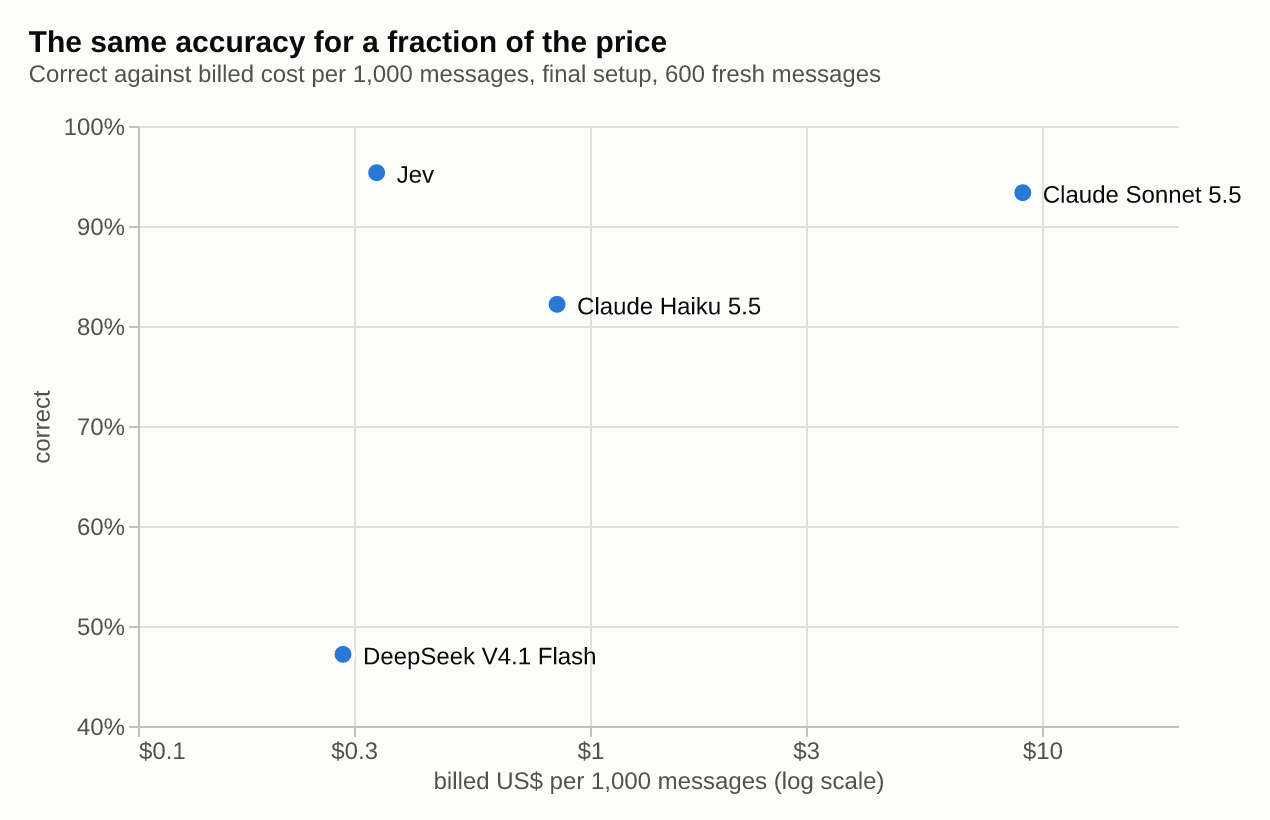

In [34]:
ops = pd.DataFrame({name: {"correct": d.right.mean(), "cost": 1000 * d.cost_usd.mean(), "median seconds": d.latency_s.median(),
                           "95th percentile seconds": d.latency_s.quantile(0.95), "input tokens": d.input_tokens.median(),
                           "US$ per month at 100,000 messages": 100_000 * d.cost_usd.mean()} for name, d in scored.items()}).T
ratio = ops.loc["Claude Sonnet 5.5", "cost"] / ops.loc["Jev", "cost"]
jev_pick = scored["Jev"]
total = sum(json.loads(line).get("cost_usd") or 0 for path in tp.RUNS.rglob("*.jsonl") for line in path.open())
print(f"Sonnet costs {ratio:.0f} times what Jev does per message")
print(f"every call ever made for this study, development included: ${total:.2f}")
print(f"Jev's pick alone: {jev_pick.pick_latency_s.median():.2f} s and ${1000 * jev_pick.pick_cost_usd.mean():.2f} per 1,000; "
      f"the argument-filling call adds {jev_pick.fill_latency_s.median():.1f} s and ${1000 * jev_pick.fill_cost_usd.mean():.3f}")
display(ops.rename(columns={"cost": "US$ per 1,000"}).style.format(
    {"correct": "{:.1%}", "US$ per 1,000": "${:.2f}", "median seconds": "{:.1f}", "95th percentile seconds": "{:.1f}",
     "input tokens": "{:,.0f}", "US$ per month at 100,000 messages": "${:,.0f}"}))
charts.cost_scatter(ops, "The same accuracy for a fraction of the price",
                    "Correct against billed cost per 1,000 messages, final setup, 600 fresh messages")

Sonnet reads 76,000 tokens of tool schemas on every call. Prompt caching makes that affordable, not cheap. Jev
reads names and descriptions only, about a tenth as much, at a much lower token price. At 100,000 messages a
month the difference is about US$900 against US$35.

For a sense of scale, everything in this repository (every development run, experiment and the final runs)
cost about US$30 in API calls.

## What I would take to production

1. **Write the routing policy down and give it to every model.** It was worth 7 to 33 points and removed most
   harmful answers. Until then I was measuring each model's guess at the policy.
2. **Describe tools in the customer's words.** One line on six tools beat every structural change to the prompt.
3. **Audit the answer key before believing a ranking.** Checking every failure by hand moved scores by up to
   15 points and reordered the selectors. The key is part of the system under test.
4. **Split misses into benign and harmful.** A hand-off and a wrong refund are not the same miss, and a single
   accuracy number can't tell them apart.
5. **Decide how the model may answer before comparing models.** Router against agent was a 44-point swing for
   the same model, larger than any difference between models.
6. **Run the cheap baseline first.** A naive Bayes classifier tied the leaders. With labelled history and
   stable intents, that may be the right answer. A model that reads tool descriptions pays off when the tools
   change faster than the labels.
7. **Compare on the same messages, with a paired test, on data the setup has never seen**, and say plainly
   when the answer is a tie.

## What I would do next

- Run Haiku and Sonnet as routers on the fresh messages, to separate mode from model.
- Three full repeats, to put a run-to-run noise figure next to every number.
- Real, multi-turn conversations with a tool list from one actual store, scored on the outcome of the whole
  conversation and not the first call.
- A test where the tools change between development and test, which is where zero-shot selection should beat
  a trained classifier.

The other notebook here, `rerun_failures.ipynb`, re-sends sampled failures of each selector to see which ones
repeat. `ledger/index.html` lets you filter and read every one of the decisions scored above.